### Notebook 4: Research Question 3: The moment a lead arrives, can the leads be ranked in a way that displays a disproportionate amount of conversions and displaying how the conversions fall under top 10%, 20% and 30%.

Input: Lead_Population_90d.csv

Approach:
1. Check the inputs for the model
2. Split it by date: train, validation, and test
3. perpare the inputs 1 for one-hot encoding along with target encoding(train data)
4. 2 baselines: random order, and channel conversion rate
5. Logistic regression model
6. Evaluate the percentages of teh conversions in the top 10%,20%, and 30%, along with the PR-AUC

Output: displaying the results table comparing the model against the baselines along with a cumulative gains chart

In [1]:
#First I loaded the lead population file from notebook 01
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv('/content/Lead_Population_90d.csv')
df['first_contact_date'] = pd.to_datetime(df['first_contact_date'])
df['origin'] = df['origin'].fillna('missing')

print(df.shape)

(6198, 9)


In [2]:
#First I went thorugh how many leads each landing page have

landing_page_count = df['landing_page_id'].value_counts()
print('distinct landing pages:', len(landing_page_count))
print('pages with only 1 lead:', (landing_page_count == 1).sum())
print('median leads per page:', landing_page_count.median())

distinct landing pages: 414
pages with only 1 lead: 231
median leads per page: 1.0


In [3]:
#Now I look at the weekday of first contact and a redo of the chi-square from milestone 2
df['day_name'] = df['first_contact_date'].dt.day_name()

table_day = pd.crosstab(df['day_name'], df['converted'])
result_day = stats.chi2_contingency(table_day)

print('chi-square:', round(result_day[0], 1))
print('df:', result_day[2])
print('p-value:', round(result_day[1], 3))
print('Cramers V:' , round((result_day[0] / len(df)) ** 0.5, 3))

chi-square: 14.2
df: 6
p-value: 0.028
Cramers V: 0.048


In [4]:
#In this cell I did a chronological split, where December - May is the train split, April being the validation split, and the test being done on the month of May

train = df[df['first_contact_date'] < '2018-04-01']
valid = df[(df['first_contact_date'] >= '2018-04-01') & (df['first_contact_date'] < '2018-05-01')]
test = df[df['first_contact_date'] >= '2018-05-01']

for name, part in [('train', train), ('validation', valid), ('test', test)]:
    print(name, ':', part['first_contact_date'].min().date(), 'to', part['first_contact_date'].max().date(),
          ' leads:', len(part), ', conversion rate:', round(100 * part['converted'].mean(), 1), '%')

print('total:', len(train) + len(valid) + len(test))

train : 2017-12-01 to 2018-03-31  leads: 3543 , conversion rate: 11.4 %
validation : 2018-04-01 to 2018-04-30  leads: 1352 , conversion rate: 12.6 %
test : 2018-05-01 to 2018-05-31  leads: 1303 , conversion rate: 8.4 %
total: 6198


In [5]:
#We now encode the text imputs as numbers, this was done so that the encoders learn only from the Train to prevent any leakage occuring
#Then I do a One-hot encode on the origin and weekday as they are unordered categories
#For the target encoding I use the landing page and its conversion rate from the train data
#lastly I combine them both onehot and te and put them side by side


import numpy as np
from sklearn.preprocessing import OneHotEncoder, TargetEncoder

onehot = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
X_train_cat = onehot.fit_transform(train[['origin', 'day_name']])
X_valid_cat = onehot.transform(valid[['origin', 'day_name']])
X_test_cat = onehot.transform(test[['origin', 'day_name']])

te = TargetEncoder(target_type='binary', random_state=42)
X_train_landing_page = te.fit_transform(train[['landing_page_id']], train['converted'])
X_valid_landing_page = te.transform(valid[['landing_page_id']])
X_test_landing_page = te.transform(test[['landing_page_id']])

# Put the columns side by side into one input table per set
X_train = np.hstack([X_train_cat, X_train_landing_page])
X_valid = np.hstack([X_valid_cat, X_valid_landing_page])
X_test = np.hstack([X_test_cat, X_test_landing_page])

y_train = train['converted']
y_valid = valid['converted']
y_test = test['converted']

print('train:', X_train.shape, ', validation:', X_valid.shape, ', test:', X_test.shape)

train: (3543, 19) , validation: (1352, 19) , test: (1303, 19)


In [6]:
#Creating a function to capture what percentage of conversions fall in the top percent of ranked leads.
#Creating 2 baselines, 1 for random order so that its fixed so results repeat and the second baseline to see each lear scored by its channel's convrsion rate according to the train data.

def capture_rate(y_true, scores, top_pct):
    ranked = pd.DataFrame({'converted': y_true.values, 'score': scores})
    ranked = ranked.sort_values('score', ascending=False)
    n_top = int(len(ranked) * top_pct)
    return round(100 * ranked['converted'].head(n_top).sum() / ranked['converted'].sum(), 1)

random_scores = np.random.default_rng(42).random(len(test))

origin_rates = train.groupby('origin')['converted'].mean()
origin_scores = test['origin'].map(origin_rates).fillna(y_train.mean()).values

for pct in [0.10, 0.20, 0.30]:
    print(f'top {int(pct*100)}% | random: {capture_rate(y_test, random_scores, pct)}% '
          f'| channel rate: {capture_rate(y_test, origin_scores, pct)}% of conversions')

top 10% | random: 6.4% | channel rate: 18.3% of conversions
top 20% | random: 13.8% | channel rate: 33.0% of conversions
top 30% | random: 22.9% | channel rate: 45.9% of conversions


In [7]:
#Training a logistic regression on the training months and checking it on the validation month being April
#Creating valid scores to see the probability of converting within the 90 days target.

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score

model = LogisticRegression(class_weight='balanced', max_iter=1000)
model.fit(X_train, y_train)

valid_scores = model.predict_proba(X_valid)[:, 1]
valid_origin_scores = valid['origin'].map(origin_rates).fillna(y_train.mean()).values

print('Validation (April)')
print('PR-AUC | model:', round(average_precision_score(y_valid, valid_scores), 3),
      '| channel rate:', round(average_precision_score(y_valid, valid_origin_scores), 3),
      '| random:', round(y_valid.mean(), 3))
for pct in [0.10, 0.20, 0.30]:
    print(f'top {int(pct*100)}% | model: {capture_rate(y_valid, valid_scores, pct)}% '
          f'| channel rate: {capture_rate(y_valid, valid_origin_scores, pct)}%')

Validation (April)
PR-AUC | model: 0.21 | channel rate: 0.167 | random: 0.126
top 10% | model: 18.1% | channel rate: 16.4%
top 20% | model: 35.7% | channel rate: 29.8%
top 30% | model: 53.2% | channel rate: 40.9%


                method  top 10%  top 20%  top 30%  PR-AUC
0    random (expected)     10.0     20.0     30.0   0.084
1         channel rate     18.3     33.0     45.9   0.126
2  logistic regression     20.2     45.9     58.7   0.159


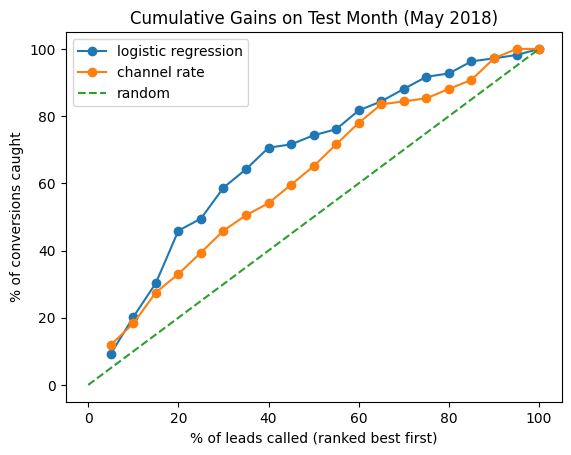

In [8]:
#Now we do the final evaluation on the test month(May)
test_scores = model.predict_proba(X_test)[:, 1]
def summarize(name, scores):
    return {'method': name,
            'top 10%': capture_rate(y_test, scores, 0.10),
            'top 20%': capture_rate(y_test, scores, 0.20),
            'top 30%': capture_rate(y_test, scores, 0.30),
            'PR-AUC': round(average_precision_score(y_test, scores), 3)}

# Results table: random (expected values), channel rate, logistic regression
random_row = {'method': 'random (expected)', 'top 10%': 10.0, 'top 20%': 20.0,
              'top 30%': 30.0, 'PR-AUC': round(y_test.mean(), 3)}
results = pd.DataFrame([random_row,
                        summarize('channel rate', origin_scores),
                        summarize('logistic regression', test_scores)])
print(results)

# Cumulative gains chart: % of leads called vs % of conversions caught
pcts = np.arange(0.05, 1.01, 0.05)
model_line = []
channel_line = []
for p in pcts:
    model_line.append(capture_rate(y_test, test_scores, p))
    channel_line.append(capture_rate(y_test, origin_scores, p))

plt.plot(pcts * 100, model_line, marker='o', label='logistic regression')
plt.plot(pcts * 100, channel_line, marker='o', label='channel rate')
plt.plot([0, 100], [0, 100], linestyle='--', label='random')
plt.title('Cumulative Gains on Test Month (May 2018)')
plt.xlabel('% of leads called (ranked best first)')
plt.ylabel('% of conversions caught')
plt.legend()
plt.show()